# A retail survey with partworth

A supermarket chain plans to sell drip coffee under its own store brand.
Before the launch, the marketing team has four questions.

1. What do shoppers look at most: brand, roast, an organic label or price?
2. How many shoppers will pick the store brand over the two maker brands?
3. Which price gives the most profit?
4. Is an organic label worth its extra cost?

The team runs a choice survey (choice-based conjoint) to answer them.
This notebook goes through the analysis with [partworth](https://github.com/kojikojikojikoji/partworth).

All data in this notebook is dummy data. A random number generator makes it in step 1.
No real survey, company or product is used.

A Japanese version of this notebook is in [retail_survey_ja.ipynb](retail_survey_ja.ipynb).

## Setup

partworth is not on PyPI yet. Install it from GitHub. The charts need matplotlib.

```
pip install "partworth[nutpie] @ git+https://github.com/kojikojikojikoji/partworth" "matplotlib>=3.10"
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import partworth as pw

The next cell sets the look of the charts. It has no effect on the results.

In [2]:
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E6E6", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11,
})
COLOR = {"Store brand": "#0F6E84", "Maker A": "#D9793D", "Maker B": "#8A6FB0", "NONE": "#B8BDC4"}
LEVEL_COLOR = ["#0F6E84", "#D9793D", "#8A6FB0"]


def share_bars(ax, table, offset=0.0, height=0.6, outline=False):
    """Horizontal bars of shares with their 90% credible intervals."""
    y = np.arange(len(table)) + offset
    if outline:
        ax.barh(y, table["share"] * 100, height=height, facecolor="none", edgecolor="#555555")
    else:
        ax.barh(y, table["share"] * 100, height=height, color=[COLOR[p] for p in table.index])
    ax.errorbar(table["share"] * 100, y, fmt="none", ecolor="#333333", capsize=3, linewidth=1,
                xerr=[(table["share"] - table["lower"]) * 100,
                      (table["upper"] - table["share"]) * 100])
    ax.set_yticks(np.arange(len(table)), table.index)
    ax.set_ylim(len(table) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("share of shoppers (%)")

## 1. The survey

400 shoppers answer 10 questions each. Every question shows three coffee products and
an "I would buy none of these" option. The shopper picks one.

Each product is described by four attributes.

| Attribute | Levels |
|---|---|
| `brand` | `store_brand`, `maker_a`, `maker_b` |
| `roast` | `light`, `medium`, `dark` |
| `organic` | `no`, `yes` |
| `price` | 398, 498, 598 or 698 yen for a pack of 10 bags |

The survey also asks if the shopper uses the store's loyalty app (`member`).

The next cell makes the dummy answers. Each dummy shopper has their own tastes. For example,
some like dark roast and some care a lot about price. App members like the store brand a
little more. With a real survey you skip this cell and load your own file.

In [3]:
rng = np.random.default_rng(7)
N, T, J = 400, 10, 3                       # shoppers, questions, products per question
levels = {
    "brand": ["store_brand", "maker_a", "maker_b"],
    "roast": ["light", "medium", "dark"],
    "organic": ["no", "yes"],
}
prices = [398, 498, 598, 698]
member = rng.random(N) < 0.4               # 40% use the loyalty app

# What each shopper likes. One row per shopper, one column per level.
taste = {
    "brand": np.column_stack([rng.normal(0.6 * member, 0.9),
                              rng.normal(0.5, 0.9, N),
                              rng.normal(0.2, 0.9, N)]),
    "roast": np.column_stack([rng.normal(0.0, 0.7, N),
                              rng.normal(0.4, 0.7, N),
                              rng.normal(0.1, 0.7, N)]),
    "organic": np.column_stack([np.zeros(N), rng.normal(0.5, 0.8, N)]),
}
per_100_yen = -np.exp(rng.normal(np.log(0.8), 0.4, N))   # how much one shopper dislikes +100 yen
no_purchase = rng.normal(0.3, 0.8, N)                    # how attractive "buy none" is

# Show random products in every question and let each shopper choose.
picks = {a: rng.integers(len(v), size=(N, T, J)) for a, v in levels.items()}
price = rng.choice(prices, size=(N, T, J))
who = np.arange(N)[:, None, None]
utility = sum(taste[a][who, picks[a]] for a in levels)
utility = utility + per_100_yen[:, None, None] * (price - 548) / 100
utility = np.concatenate(
    [utility, np.broadcast_to(no_purchase[:, None, None], (N, T, 1))], axis=2)
choice = (utility + rng.gumbel(size=utility.shape)).argmax(axis=2)   # 0 to 2: a product, 3: none

# Put the answers in a long table: one row per shopper, question and option.
i, t, j = np.meshgrid(np.arange(N), np.arange(T), np.arange(J), indexing="ij")
products = pd.DataFrame({
    "respondent": i.ravel() + 1, "question": t.ravel() + 1, "option": j.ravel() + 1,
    **{a: np.array(v)[picks[a].ravel()] for a, v in levels.items()},
    "price": price.ravel(), "no_purchase": False,
})
i, t = np.meshgrid(np.arange(N), np.arange(T), indexing="ij")
nones = pd.DataFrame({"respondent": i.ravel() + 1, "question": t.ravel() + 1,
                      "option": J + 1, "no_purchase": True})
survey = pd.concat([products, nones]).sort_values(
    ["respondent", "question", "option"], ignore_index=True)
picked = choice[survey["respondent"] - 1, survey["question"] - 1] + 1
survey["chosen"] = (survey["option"] == picked).astype(int)
survey["price"] = survey["price"].astype("Int64")        # whole yen; empty on the "buy none" rows

shoppers = pd.DataFrame({"member": np.where(member, "yes", "no")},
                        index=pd.Index(np.arange(1, N + 1), name="respondent"))

This is the first question of the first shopper. Options 1 to 3 are products and option 4
is "buy none". `chosen` is 1 for the option the shopper picked.

In [4]:
survey.head(4)

,respondent,question,option,brand,roast,organic,price,no_purchase,chosen
0,1,1,1,maker_b,medium,yes,698,False,0
1,1,1,2,store_brand,dark,no,698,False,0
2,1,1,3,store_brand,medium,yes,498,False,0
3,1,1,4,NaN,NaN,NaN,<NA>,True,1


## 2. Load and check the data

`ChoiceData.from_long` reads the long table and checks it. For example, every question must
have exactly one chosen option.

- `pw.Categorical` is for attributes with named levels.
- `pw.Linear(sign="negative")` treats price as a number. It also tells the model that a
  higher price never makes a product more attractive.
- `covariates` holds facts about each shopper. Here it is app membership.

In [5]:
data = pw.ChoiceData.from_long(
    survey,
    attributes={
        "brand": pw.Categorical(levels["brand"]),
        "roast": pw.Categorical(levels["roast"]),
        "organic": pw.Categorical(levels["organic"]),
        "price": pw.Linear(sign="negative"),
    },
    respondent="respondent", task="question", alternative="option", chosen="chosen",
    none="no_purchase",
    covariates=shoppers,
)
data

ChoiceData(respondents=400, max_tasks=10, max_alternatives=4, params=7, covariates=1)

`describe()` counts how often each level was shown and chosen. Look at it before you fit
a model. A level that was shown only a few times cannot be estimated well.

The raw rates already show a pattern. Products at 398 yen were chosen about four times as
often as products at 698 yen.

In [6]:
data.describe().round(3)

,attribute,level,shown,chosen,rate
0,brand,store_brand,4027,1032,0.256
1,brand,maker_a,3967,1156,0.291
2,brand,maker_b,4006,1055,0.263
3,roast,light,3902,961,0.246
4,roast,medium,4014,1230,0.306
5,roast,dark,4084,1052,0.258
6,organic,no,5986,1378,0.230
7,organic,yes,6014,1865,0.310
8,price,398,2881,1357,0.471
9,price,498,3027,956,0.316


## 3. Fit the model

The model is a hierarchical Bayes multinomial logit. In plain words: every shopper gets
their own set of preferences. Ten answers are not many, so the model also uses what it
learns from the other shoppers.

Always read the diagnostics before the results. The report says if the sampler converged
and what to try if it did not. This fit takes about one minute on a laptop.

The last lines of the report are about the correlations between preferences. They need
more draws than the other results. This notebook does not report correlations, so we go on.

In [7]:
result = pw.HierarchicalMNL(data).fit(draws=2000, tune=3000, chains=4, random_seed=1)
print(result.diagnostics().report())

converged
R-hat max      1.006  (target < 1.01)
ESS bulk min   1380  (target > 400)
ESS tail min   1736  (target > 400)
divergences    0  (target 0)
worst variable tau
correlations   R-hat max 1.013, ESS bulk min 597
what to try:
- correlations have not reached the targets: part-worths, shares and WTP are unaffected, but rerun with more draws (e.g. 3000) before reporting correlations


## 4. What do shoppers look at most?

`importances()` gives the importance of each attribute for every shopper, in percent.
In the chart, one shape shows all 400 shoppers. A wide shape means that shoppers differ.
The dot is the median. The table below the chart shows the average.

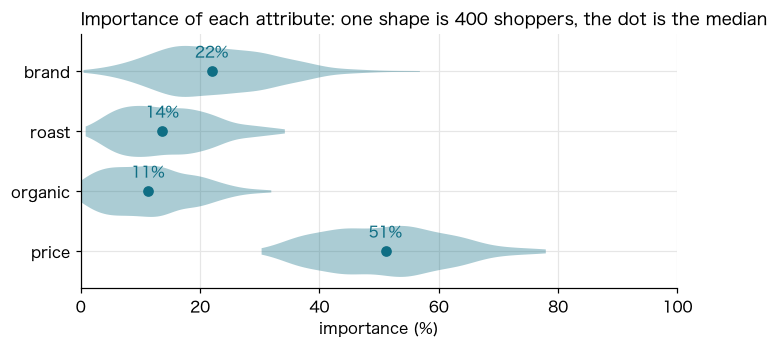

brand      22.7
roast      14.5
organic    11.6
price      51.2
dtype: float64

In [8]:
importance = result.importances()

fig, ax = plt.subplots(figsize=(7, 3))
parts = ax.violinplot([importance[a] for a in importance.columns], orientation="horizontal",
                      showextrema=False, widths=0.85)
for body in parts["bodies"]:
    body.set_facecolor("#0F6E84")
    body.set_alpha(0.35)
medians = importance.median()
ax.scatter(medians, np.arange(1, len(medians) + 1), color="#0F6E84", zorder=3)
for k, (name, value) in enumerate(medians.items(), start=1):
    ax.annotate(f"{value:.0f}%", (value, k), textcoords="offset points", xytext=(0, 9),
                ha="center", color="#0F6E84")
ax.set_yticks(np.arange(1, len(medians) + 1), importance.columns)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("importance (%)")
ax.set_title("Importance of each attribute: one shape is 400 shoppers, the dot is the median")
plt.show()

importance.mean().round(1)

Price matters most on average. The shapes are wide, so shoppers differ a lot. For a few
shoppers (19 of 400) brand matters more than price.

The importance of price depends on the price range in the survey. A wider range gives a
higher number.

## 5. How much do shoppers differ?

An average hides the differences between shoppers. This model estimates the preferences of
every single shopper, so we can look at them.

`part_worths()` shows the preference for each level. One row is one shopper. A higher
number means the shopper likes that level more. The price column is the change for one yen.
The NONE column is large and negative because it is compared with a product at 0 yen.

In [9]:
result.part_worths().head().round(3)

attribute        brand                  roast               organic         \
level      store_brand maker_a maker_b  light medium   dark      no    yes   
respondent                                                                   
1               -0.746   0.871  -0.125 -0.526  0.609 -0.083   0.224 -0.224   
2               -0.050  -0.260   0.310 -0.517  0.491  0.026  -0.243  0.243   
3               -0.678  -0.285   0.963  0.087 -0.440  0.353  -0.530  0.530   
4                0.549  -0.800   0.251 -0.774  0.680  0.093  -0.263  0.263   
5               -0.610   0.902  -0.292 -0.619  0.397  0.222  -0.031  0.031   

attribute   price   NONE  
level       slope   NONE  
respondent                
1          -0.008 -2.514  
2          -0.012 -6.961  
3          -0.007 -4.656  
4          -0.007 -4.768  
5          -0.009 -4.511

The table shows one average estimate per shopper. The model pulls these averages towards
the overall average, so they look more alike than the shoppers really are.

To see the spread, the next chart uses the posterior draws of every shopper. Each colour
is one level.

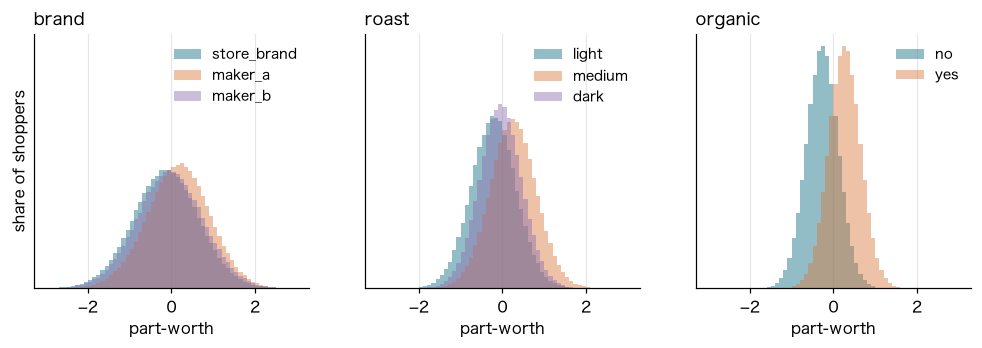

like medium roast best: 51% of shoppers
like the organic label: 76% of shoppers


In [10]:
# Every tenth posterior draw, with one row per draw and shopper.
draws = result.beta_draws()[::10]
by_draw = data.codebook.expand(draws)


def per_shopper(column):
    """One column of the table as an array: rows are draws, columns are shoppers."""
    return by_draw[column].to_numpy().reshape(len(draws), N)


fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, attribute in zip(axes, ["brand", "roast", "organic"]):
    for level, color in zip(levels[attribute], LEVEL_COLOR):
        ax.hist(per_shopper((attribute, level)).ravel(), bins=np.linspace(-3, 3, 61),
                density=True, histtype="stepfilled", alpha=0.45, color=color, label=level)
    ax.set_title(attribute)
    ax.set_xlabel("part-worth")
    ax.set_yticks([])
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("share of shoppers")
plt.show()

roast = np.stack([per_shopper(("roast", level)) for level in levels["roast"]])
likes_label = per_shopper(("organic", "yes")) > per_shopper(("organic", "no"))
print(f"like medium roast best: {np.mean(roast.argmax(axis=0) == 1):.0%} of shoppers")
print(f"like the organic label: {np.mean(likes_label):.0%} of shoppers")

Read the width of each shape.

- `brand` is wide and the three shapes overlap. No brand wins with everyone.
- `roast`: about half of the shoppers like `medium` best.
- `organic`: the two shapes mirror each other, because an attribute with two levels has
  one difference. About three in four shoppers like the label. Step 10 shows how much they
  would pay for it.

The chart pools the draws of every shopper. So it shows the differences between shoppers
and the uncertainty of the estimates together. Do not compare the widths of attributes
with a different number of levels.

The next chart puts two of these preferences on one scatter plot. Each dot is one shopper.

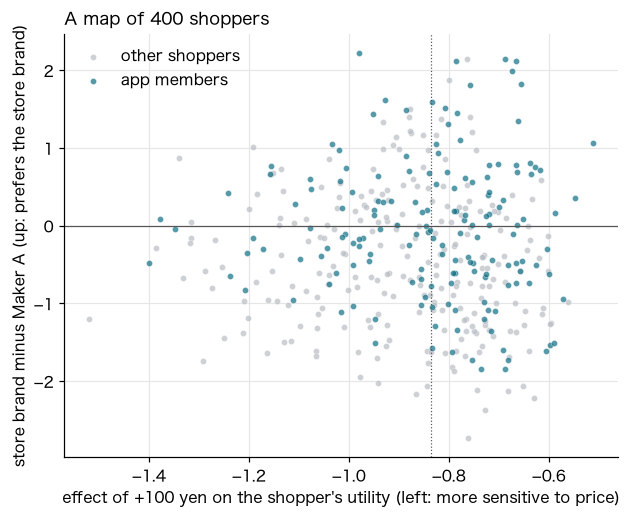

prefer the store brand to Maker A, app members: 48% (90% interval 41 to 55%)
prefer the store brand to Maker A, other shoppers: 36% (90% interval 30 to 41%)


In [11]:
part_worths = result.part_worths()
price_effect = part_worths[("price", "slope")] * 100          # per 100 yen
brand_gap = part_worths[("brand", "store_brand")] - part_worths[("brand", "maker_a")]
is_app_member = (shoppers["member"] == "yes").to_numpy()

fig, ax = plt.subplots(figsize=(6.5, 5))
for mask, color, label in [(~is_app_member, "#B8BDC4", "other shoppers"),
                           (is_app_member, "#0F6E84", "app members")]:
    ax.scatter(price_effect[mask], brand_gap[mask], s=16, alpha=0.7, color=color,
               edgecolor="white", linewidth=0.3, label=label)
ax.axhline(0, color="#555555", linewidth=0.8)
ax.axvline(price_effect.median(), color="#555555", linewidth=0.8, linestyle=":")
ax.set_xlabel("effect of +100 yen on the shopper's utility (left: more sensitive to price)")
ax.set_ylabel("store brand minus Maker A (up: prefers the store brand)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("A map of 400 shoppers")
plt.show()

gap_draws = per_shopper(("brand", "store_brand")) - per_shopper(("brand", "maker_a"))
for label, mask in [("app members", is_app_member), ("other shoppers", ~is_app_member)]:
    share = np.mean(gap_draws[:, mask] > 0, axis=1) * 100       # one value per draw
    print(f"prefer the store brand to Maker A, {label}: {share.mean():.0f}% "
          f"(90% interval {np.quantile(share, 0.05):.0f} to {np.quantile(share, 0.95):.0f}%)")

Dots in the upper half are shoppers who like the store brand more than Maker A.
Dots on the left are more sensitive to price.

The coloured dots are app members. More of them are in the upper half. The dots are spread
over the whole chart, so there is no single "typical shopper".

A dot is the average estimate for one shopper. The model pulls these averages towards the
overall average, so the dots are closer together than the shoppers really are. To count
shoppers, use the posterior draws, as in the last lines of the cell. 48% of app members
prefer the store brand to Maker A (90% interval 41 to 55%). For the other shoppers it is
36% (30 to 41%).

## 6. Who wins on the shelf?

Now put three products on a shelf and ask the simulator how shoppers choose.
`shares()` gives the share of each product with a 90% credible interval.

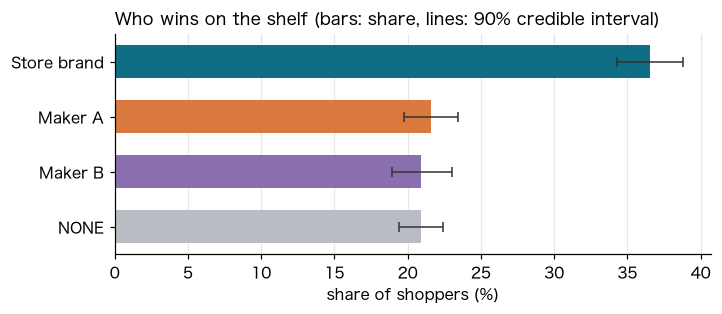

,share,lower,upper
product,,,
Store brand,0.366,0.343,0.388
Maker A,0.216,0.198,0.234
Maker B,0.209,0.189,0.230
NONE,0.209,0.194,0.224


In [12]:
shelf = pd.DataFrame({
    "product": ["Store brand", "Maker A", "Maker B"],
    "brand": ["store_brand", "maker_a", "maker_b"],
    "roast": ["medium", "medium", "dark"],
    "organic": ["no", "no", "yes"],
    "price": [498, 598, 648],
})
sim = pw.MarketSimulator(result)
shelf_shares = sim.shares(shelf).set_index("product")

fig, ax = plt.subplots(figsize=(7, 2.6))
share_bars(ax, shelf_shares)
ax.set_title("Who wins on the shelf (bars: share, lines: 90% credible interval)")
plt.show()

shelf_shares.round(3)

At 498 yen, about 37 of 100 shoppers pick the store brand. About 21 buy nothing.

These are shares of choices in the survey. They are not a sales forecast. Real sales also
depend on things the survey does not cover, such as shelf position, stock and promotions.

## 7. Where does the store brand take its share from?

Simulate the shelf before the launch, with the two maker brands only. Then compare it with
the shelf after the launch.

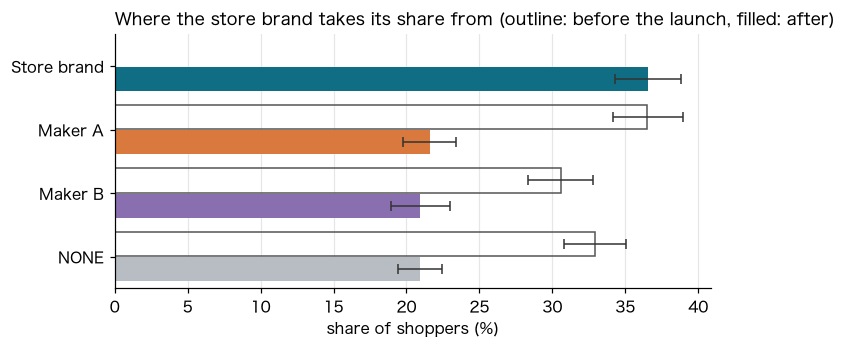

,change in share (points)
product,
Store brand,36.6
Maker A,-14.9
Maker B,-9.6
NONE,-12.0


In [13]:
before = sim.shares(shelf.iloc[1:]).set_index("product")       # the shelf without the store brand
before = before.reindex(shelf_shares.index).fillna(0.0)

fig, ax = plt.subplots(figsize=(7, 3))
share_bars(ax, before, offset=-0.2, height=0.38, outline=True)
share_bars(ax, shelf_shares, offset=0.2, height=0.38)
ax.set_title("Where the store brand takes its share from (outline: before the launch, filled: after)")
plt.show()

change = ((shelf_shares["share"] - before["share"]) * 100).round(1)
change.rename("change in share (points)").to_frame()

The share of the store brand goes from 0% to about 37%. About 15 points come from
Maker A and about 10 from Maker B. The other 12 points come from shoppers who bought
nothing before.

So about one third of the store brand's buyers are new coffee buyers for the store. The
other two thirds switch from a maker brand. Whether that switch is good for the store
depends on the margin of each product.

This split follows from the logit rule of the simulator. A new product takes share from
every option in proportion, shopper by shopper. Treat the one third as the model's
estimate. It is not a measured number.

## 8. Which price gives the most profit?

Suppose one pack costs the store 300 yen. Then the profit from 100 shoppers is
`share x 100 x (price - 300)`.

The model does not give one answer. It gives 8,000 posterior draws. Each draw is one set
of shopper preferences that fits the data. The simulator uses 500 of them, evenly spaced,
and `share_draws()` returns the shares for each of these 500 draws. We move the price of the store brand in steps of 25 yen and keep the rest of the
shelf fixed. Then we ask in each draw which price gives the most profit.

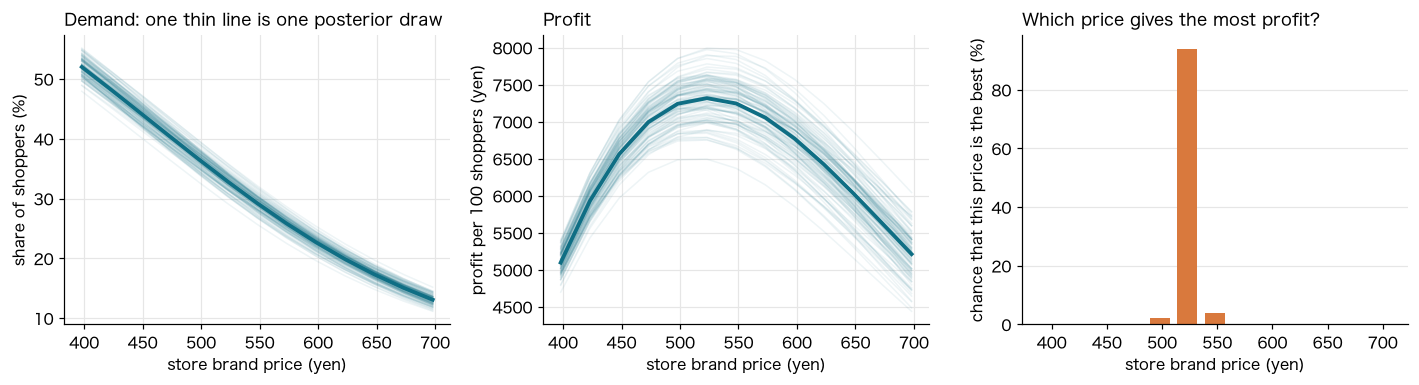

,share,profit,chance_best
price,,,
398,0.520,5097.695,0.000
423,0.482,5930.524,0.000
448,0.443,6562.136,0.000
473,0.404,6996.051,0.000
498,0.366,7242.475,0.022
523,0.328,7318.421,0.940
548,0.292,7246.970,0.038
573,0.258,7055.396,0.000
598,0.227,6772.295,0.000


In [14]:
unit_cost = 300
grid = np.arange(398, 699, 25)


def store_brand_draws(price, base=shelf):
    """Share of the store brand at one price, for every posterior draw."""
    scenario = base.copy()
    scenario.loc[0, "price"] = price
    return sim.share_draws(scenario)["Store brand"].to_numpy()


share_by_price = np.column_stack([store_brand_draws(p) for p in grid])   # rows: draws, columns: prices
profit_by_price = share_by_price * 100 * (grid - unit_cost)
best_price = grid[profit_by_price.argmax(axis=1)]                        # the best price in each draw

fig, (left, middle, right) = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, values, label in [(left, share_by_price * 100, "share of shoppers (%)"),
                          (middle, profit_by_price, "profit per 100 shoppers (yen)")]:
    ax.plot(grid, values[::5].T, color="#0F6E84", alpha=0.07, linewidth=1)
    ax.plot(grid, values.mean(axis=0), color="#0F6E84", linewidth=2.5)
    ax.set_xlabel("store brand price (yen)")
    ax.set_ylabel(label)
left.set_title("Demand: one thin line is one posterior draw")
middle.set_title("Profit")
chance = pd.Series(best_price).value_counts(normalize=True).reindex(grid, fill_value=0) * 100
right.bar(grid, chance, width=18, color="#D9793D")
right.set_xlabel("store brand price (yen)")
right.set_ylabel("chance that this price is the best (%)")
right.set_title("Which price gives the most profit?")
right.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

pd.DataFrame({"share": share_by_price.mean(axis=0), "profit": profit_by_price.mean(axis=0),
              "chance_best": chance.to_numpy() / 100}, index=pd.Index(grid, name="price")).round(3)

The left chart is the demand curve. The share falls from about 52% at 398 yen to about
13% at 698 yen. The spread of the thin lines is the uncertainty. At 523 yen the share is
between 31% and 35% in 90% of the draws.

The middle chart is the profit. It has the same uncertainty, about 7% up or down. The
lines differ in height, but almost every line has its top at the same place.

The right chart counts the tops. 523 yen is the best price in 94% of the draws. The
neighbours 498 and 548 yen share the rest. The profit at these three prices differs by
about 1%, so other reasons, such as a round price, can decide between them.

The 94% holds on this grid of 25 yen, for a cost of 300 yen, for this shelf and under the
model's assumptions. One assumption is that each shopper reacts to price in a straight
line. It is not the chance that 523 yen is right in a real shop.

## 9. What if Maker A changes its price?

Maker A may change its price too. The chart below repeats the simulation for five prices
of Maker A and for each price of the store brand. Each cell is the expected profit of the
store brand.

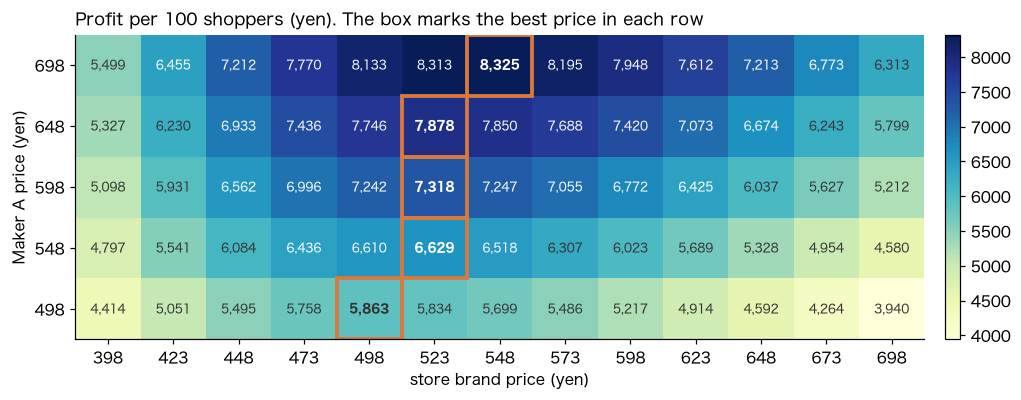

In [15]:
own_prices = grid
rival_prices = np.arange(498, 699, 50)
profit = np.empty((len(rival_prices), len(own_prices)))
for r, rival in enumerate(rival_prices):
    rival_shelf = shelf.copy()
    rival_shelf.loc[1, "price"] = rival                     # Maker A changes its price
    for c, own in enumerate(own_prices):
        profit[r, c] = store_brand_draws(own, rival_shelf).mean() * 100 * (own - unit_cost)

fig, ax = plt.subplots(figsize=(12, 3.6))
image = ax.imshow(profit, cmap="YlGnBu", aspect="auto", origin="lower")
for r in range(len(rival_prices)):
    best = profit[r].argmax()
    for c in range(len(own_prices)):
        ax.text(c, r, f"{profit[r, c]:,.0f}", ha="center", va="center", fontsize=8,
                color="white" if profit[r, c] > profit.mean() else "#333333",
                fontweight="bold" if c == best else "normal")
    ax.add_patch(plt.Rectangle((best - 0.5, r - 0.5), 1, 1, fill=False,
                               edgecolor="#D9793D", linewidth=2.5))
ax.set_xticks(range(len(own_prices)), own_prices)
ax.set_yticks(range(len(rival_prices)), rival_prices)
ax.set_xlabel("store brand price (yen)")
ax.set_ylabel("Maker A price (yen)")
ax.set_title("Profit per 100 shoppers (yen). The box marks the best price in each row")
ax.grid(visible=False)
fig.colorbar(image, ax=ax, pad=0.02)
plt.show()

Read one row at a time. The box marks the best price of the store brand in that row.

The best price moves little. It is 523 yen if Maker A is at 548, 598 or 648 yen. It is
498 yen if Maker A cuts its price to 498 yen, and 548 yen if Maker A goes up to 698 yen.

The profit moves much more. Compared with the row for 598 yen, the best profit falls by
about 9% if Maker A cuts its price to 548 yen, and by about 20% at 498 yen. So the store
brand does not need to follow every price change of Maker A, but its profit depends on it.

All prices in this chart are inside the range of the survey (398 to 698 yen). Do not
simulate prices outside the range that the shoppers saw.

## 10. Is an organic label worth it?

`wtp()` gives the willingness to pay: the price increase that cancels out the gain from
the label. It reports the median shopper with a 90% credible interval.

In [16]:
organic_wtp = pw.wtp(result, attribute="organic", from_level="no", to_level="yes")
organic_wtp.round(1)

,attribute,from,to,median,lower,upper,mean,share_negative_price_slope
0,organic,no,yes,61.2,49.5,73.4,66.9,1.0


The median is about 60 yen. This is one number for the whole group. The next chart shows
how the willingness to pay differs between shoppers. It uses the posterior draws from step 5.

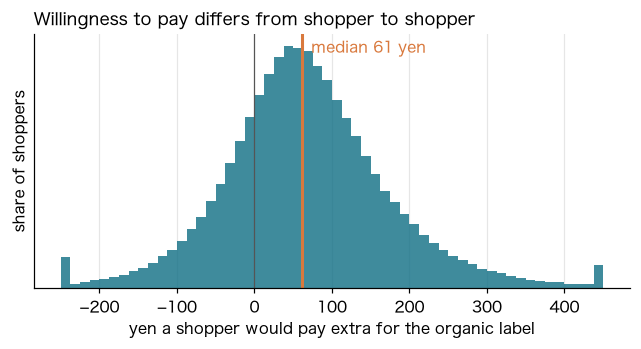

would pay nothing extra: 24% of shoppers (90% interval 18 to 30%)
would pay 100 yen or more: 34% of shoppers (90% interval 28 to 39%)


In [17]:
wtp_draws = ((per_shopper(("organic", "yes")) - per_shopper(("organic", "no")))
             / -per_shopper(("price", "slope")))                # yen, for every draw and shopper

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.clip(wtp_draws, -250, 450).ravel(), bins=np.arange(-250, 451, 12.5), density=True,
        color="#0F6E84", alpha=0.8)
ax.axvline(0, color="#555555", linewidth=0.8)
ax.axvline(np.median(wtp_draws), color="#D9793D", linewidth=2)
ax.annotate(f"median {np.median(wtp_draws):.0f} yen", (np.median(wtp_draws), ax.get_ylim()[1]),
            textcoords="offset points", xytext=(6, -12), color="#D9793D")
ax.set_yticks([])
ax.set_xlabel("yen a shopper would pay extra for the organic label")
ax.set_ylabel("share of shoppers")
ax.set_title("Willingness to pay differs from shopper to shopper")
plt.show()

for label, hit in [("would pay nothing extra", wtp_draws <= 0),
                   ("would pay 100 yen or more", wtp_draws >= 100)]:
    share = hit.mean(axis=1) * 100                              # one value per draw
    print(f"{label}: {share.mean():.0f}% of shoppers "
          f"(90% interval {np.quantile(share, 0.05):.0f} to {np.quantile(share, 0.95):.0f}%)")

The spread is wide. About one shopper in four would pay nothing extra for the label.
About one in three would pay 100 yen or more. A label with a small price increase keeps
most shoppers. A large increase keeps only the group on the right.

The chart pools every draw of every shopper. So it shows the differences between shoppers
and the uncertainty of the estimates together. The share that would pay nothing extra is
between 18% and 30% in 90% of the draws. Values outside -250 to 450 yen (about 1%) are
drawn at the edges.

The simulator can test a concrete plan. Here the store brand gets the label and its price
goes up by 50 yen. Both plans use the same posterior draws, so we compare them draw by draw.

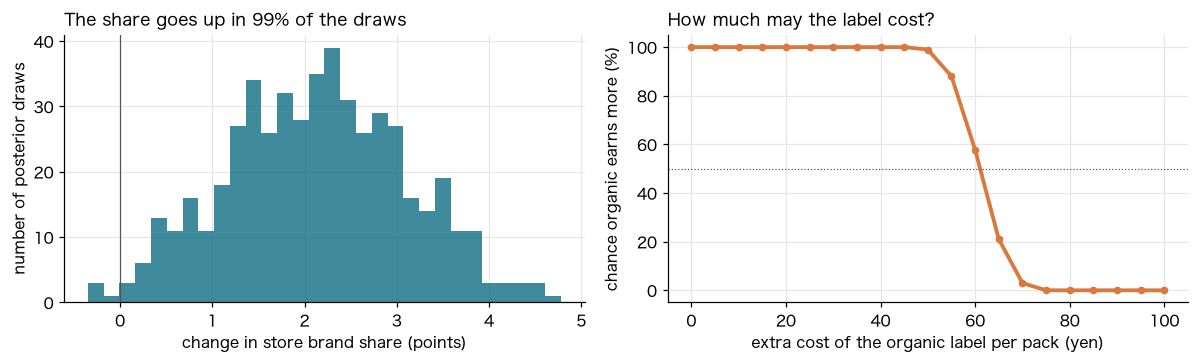

change in share: +2.1 points (90% interval +0.5 to +3.7)


In [18]:
organic_shelf = shelf.copy()
organic_shelf.loc[0, ["organic", "price"]] = ["yes", 548]

plain = sim.share_draws(shelf)["Store brand"]
organic = sim.share_draws(organic_shelf)["Store brand"]
gain = (organic - plain) * 100                              # difference in every draw, in points

# Profit of both plans if the label adds a cost of 0 to 100 yen per pack.
extra_cost = np.arange(0, 101, 5)
profit_plain = plain.to_numpy() * 100 * (498 - unit_cost)
profit_organic = organic.to_numpy()[:, None] * 100 * (548 - unit_cost - extra_cost)
chance_better = (profit_organic > profit_plain[:, None]).mean(axis=0) * 100

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.hist(gain, bins=30, color="#0F6E84", alpha=0.8)
left.axvline(0, color="#555555", linewidth=0.8)
left.set_xlabel("change in store brand share (points)")
left.set_ylabel("number of posterior draws")
left.set_title(f"The share goes up in {np.mean(gain > 0):.0%} of the draws")
right.plot(extra_cost, chance_better, color="#D9793D", linewidth=2.5, marker="o", markersize=4)
right.axhline(50, color="#555555", linewidth=0.8, linestyle=":")
right.set_xlabel("extra cost of the organic label per pack (yen)")
right.set_ylabel("chance organic earns more (%)")
right.set_title("How much may the label cost?")
plt.tight_layout()
plt.show()

print(f"change in share: {gain.mean():+.1f} points "
      f"(90% interval {gain.quantile(0.05):+.1f} to {gain.quantile(0.95):+.1f})")

The left chart shows the change in share. With the label and a price of 548 yen, the
share of the store brand goes up by about 2 points. It goes up in 99% of the draws.

Do not judge such a change from the overlap of two intervals. The intervals of the two
plans overlap, but the plans move together from draw to draw. The difference in each draw
is the right thing to look at.

The right chart shows how much the label may cost. If the label adds up to 50 yen to the
cost of a pack, the organic plan earns more in 99% of the draws. At about 60 yen the two
plans are even. From about 65 yen the plain product is more likely to earn more. Above
70 yen this is almost certain.

## 11. Do app members choose differently?

`weights` restricts the simulation to a group of shoppers. A weight of 1 keeps a shopper
and 0 drops them.

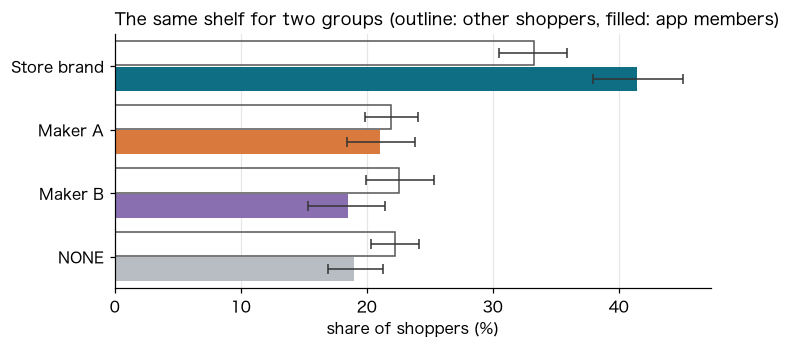

app members               other shoppers              
                  share  lower  upper          share  lower  upper
product                                                           
Store brand       0.415  0.380  0.451          0.333  0.305  0.359
Maker A           0.211  0.184  0.238          0.219  0.199  0.241
Maker B           0.185  0.154  0.215          0.226  0.200  0.253
NONE              0.190  0.169  0.213          0.222  0.203  0.242

In [19]:
is_member = (shoppers["member"] == "yes").astype(float)
members = sim.shares(shelf, weights=is_member).set_index("product")
others = sim.shares(shelf, weights=1 - is_member).set_index("product")

fig, ax = plt.subplots(figsize=(7, 3))
share_bars(ax, others, offset=-0.2, height=0.38, outline=True)
share_bars(ax, members, offset=0.2, height=0.38)
ax.set_title("The same shelf for two groups (outline: other shoppers, filled: app members)")
plt.show()

pd.concat({"app members": members, "other shoppers": others}, axis=1).round(3)

App members pick the store brand more often than other shoppers. The app is a natural
place to announce the launch.

## 12. Check against the truth

With dummy data we know the true tastes of every shopper. So we can check the estimates.
A real survey has no such answer key. Use the diagnostics in step 3 and hold-out questions
(`data.holdout(...)`) there.

organic label, median willingness to pay: true 60 yen, estimated 61 yen (90% interval 49 to 73)


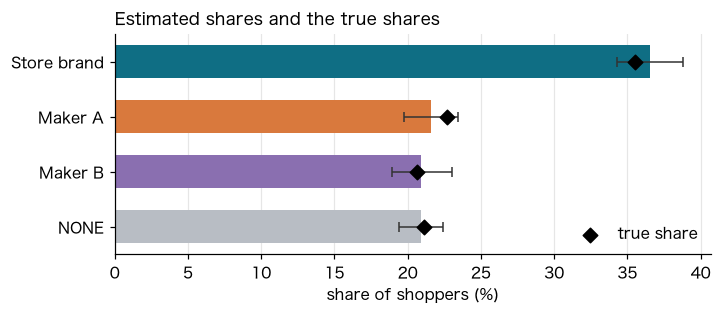

,true share,share,lower,upper
product,,,,
Store brand,0.355,0.366,0.343,0.388
Maker A,0.227,0.216,0.198,0.234
Maker B,0.207,0.209,0.189,0.230
NONE,0.211,0.209,0.194,0.224


In [20]:
true_wtp = np.median(taste["organic"][:, 1] / -per_100_yen * 100)
print(f"organic label, median willingness to pay: true {true_wtp:.0f} yen, "
      f"estimated {organic_wtp['median'][0]:.0f} yen "
      f"(90% interval {organic_wtp['lower'][0]:.0f} to {organic_wtp['upper'][0]:.0f})")

# Shares on the shelf of step 6, from the true tastes.
true_utility = np.column_stack(
    [sum(taste[a][:, levels[a].index(row[a])] for a in levels)
     + per_100_yen * (row["price"] - 548) / 100 for _, row in shelf.iterrows()]
    + [no_purchase])
true_share = np.exp(true_utility) / np.exp(true_utility).sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 2.6))
share_bars(ax, shelf_shares)
ax.scatter(true_share.mean(axis=0) * 100, np.arange(4), marker="D", s=45, color="black",
           zorder=3, label="true share")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Estimated shares and the true shares")
plt.show()

check = shelf_shares.copy()
check.insert(0, "true share", true_share.mean(axis=0))
check.round(3)

The true willingness to pay and the true shares are inside the 90% intervals. So the model
recovers the results for the whole group in this example. This is one dummy data set that
follows the model's own assumptions. A real survey will fit less well.

Results for single shoppers are less exact. The next chart shows 60 shoppers. The vertical
line is the 90% interval of the price sensitivity of one shopper, and the diamond is the true value.

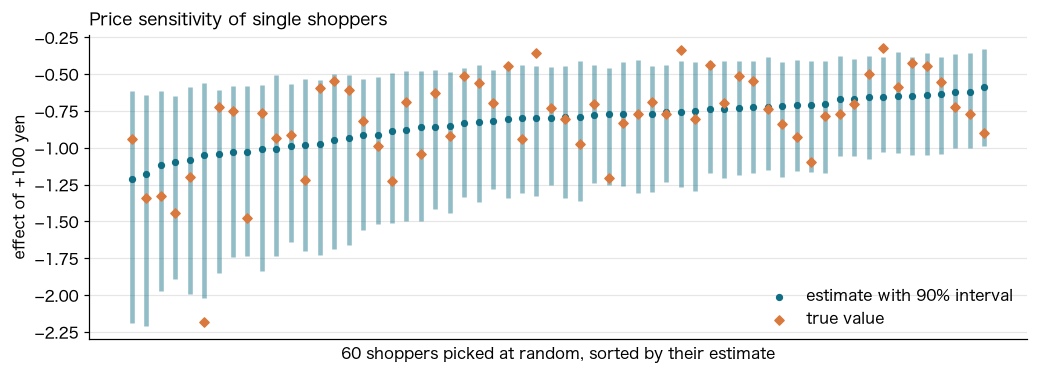

true value inside the 90% interval: 90% of the 400 shoppers
correlation of estimate and true value: 0.50


In [21]:
price_draws = per_shopper(("price", "slope")) * 100            # per 100 yen, for every draw and shopper
lower, median, upper = np.quantile(price_draws, [0.05, 0.5, 0.95], axis=0)
inside = (per_100_yen >= lower) & (per_100_yen <= upper)

show = np.sort(np.random.default_rng(0).choice(N, size=60, replace=False))
show = show[np.argsort(median[show])]
x = np.arange(len(show))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.vlines(x, lower[show], upper[show], color="#0F6E84", alpha=0.45, linewidth=3)
ax.scatter(x, median[show], color="#0F6E84", s=14, zorder=3, label="estimate with 90% interval")
ax.scatter(x, per_100_yen[show], color="#D9793D", marker="D", s=18, zorder=4, label="true value")
ax.set_xticks([])
ax.set_xlabel("60 shoppers picked at random, sorted by their estimate")
ax.set_ylabel("effect of +100 yen")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", visible=False)
ax.set_title("Price sensitivity of single shoppers")
plt.show()

print(f"true value inside the 90% interval: {inside.mean():.0%} of the 400 shoppers")
print(f"correlation of estimate and true value: {np.corrcoef(per_100_yen, median)[0, 1]:.2f}")

The intervals have the right width here. The true value is inside the 90% interval for
90% of the shoppers. But the intervals are wide. Each shopper gave just 10 answers, so the model
cannot place one shopper exactly. It also pulls single shoppers towards the average. The
correlation between the estimate and the true value is about 0.5.

Use the results for groups of shoppers, as in steps 6 to 11. Do not read much into the
numbers of one shopper.

## 13. Save the results

`to_sawtooth_csv()` writes one row per shopper in a Sawtooth-style layout.
`result.save()` keeps the full fit, so you can run new simulations later without fitting again.

```python
result.to_sawtooth_csv("retail_utilities.csv")
result.save("retail_fit.nc")
result = pw.HBResult.load("retail_fit.nc", data)
```

## Next steps

- [docs/guide.md](../docs/guide.md) explains the choices you make along the way.
- [camera.py](camera.py) runs the main steps (fit, shares, willingness to pay) on public data.